# Rural fires in Portuguese municipalities

This report studies rural-fire frequency, alert sources, and emergency response in Alij?, Mirandela, Alc?cer do Sal, and Odemira. The comparison periods are 2014?2016 and 2018?2020; 2017 is excluded as a transition year.

The planned tests are Welch's t-test for monthly counts, Welch's ANOVA for response time, a chi-square test for alert source, and a two-proportion comparison for the `Populares` alert category (the general-public category recorded by the dataset).


In [9]:
from pathlib import Path
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

DATA_PATH = Path('13-Registos-Incendios-SGIF-2011-2020') / 'Registos_Incendios_SGIF_2011_2020.xlsx'
SELECTED_MUNICIPALITIES = ['Alijó', 'Mirandela', 'Alcácer do Sal', 'Odemira']
COMPARISON_YEARS = [2014, 2015, 2016, 2018, 2019, 2020]
PUBLIC_ALERT_SOURCE = 'Populares'

if not DATA_PATH.exists():
    raise FileNotFoundError(f'Dataset not found: {DATA_PATH.resolve()}')


In [10]:
fires = pd.read_excel(DATA_PATH, sheet_name='SGIF_2011_2020')
print(f'Full dataset: {fires.shape[0]:,} rows and {fires.shape[1]} columns')
fires.head()


Full dataset: 177,129 rows and 41 columns


,Codigo_SGIF,Codigo_ANEPC,Ano,Mes,Dia,Hora,AreaPov_ha,AreaMato_ha,AreaAgric_ha,AreaTotal_ha,...,ISI,DC,DMC,FFMC,BUI,CodCausa,TipoCausa,GrupoCausa,DescricaoCausa,FonteAlerta
0,DM2111,368,2011,1,1,17,0.0,0.010,0.00000,0.01000,...,0.291930,4.092373,0.653638,54.525424,0.934234,145.0,Negligente,Uso do fogo - Fogueiras,Fogueiras - Outras,Populares
1,BL4112,1236,2011,1,9,22,0.0,0.000,0.00200,0.00200,...,0.013831,1.835452,0.367371,32.001278,0.489703,610.0,Desconhecida,Indeterminadas,Indeterminadas - Prova material,Populares
2,DM3111,820,2011,1,15,17,0.0,0.000,0.00001,0.00001,...,1.171990,9.658571,1.573768,74.889775,2.236498,124.0,Negligente,Queimas amontoados de sobrantes florestais ou ...,Queima de amontoados - Borralheiras,Populares
3,BL2111,1977,2011,1,18,22,0.0,0.001,0.00000,0.00100,...,0.248910,12.477199,0.762519,51.102608,1.322920,124.0,Negligente,Queimas amontoados de sobrantes florestais ou ...,Queima de amontoados - Borralheiras,Populares
4,DM2113,7930,2011,1,19,17,0.0,0.005,0.00000,0.00500,...,0.008092,3.968661,0.508191,32.290416,0.769912,NaN,NaN,NaN,NaN,Populares


## Data preparation

The workbook contains accent and capitalization variants in municipality names. Matching therefore uses an accent-insensitive key while preserving canonical names in the output.


In [11]:
def normalize_text(value):
    if pd.isna(value):
        return ''
    text = unicodedata.normalize('NFKD', str(value))
    return ''.join(c for c in text if not unicodedata.combining(c)).casefold().strip()

municipality_keys = {normalize_text(name): name for name in SELECTED_MUNICIPALITIES}
fires['Municipio'] = fires['Concelho'].map(
    lambda value: municipality_keys.get(normalize_text(value))
)
df = fires[
    fires['Municipio'].notna() & fires['Ano'].isin(COMPARISON_YEARS)
].copy()
df['Periodo'] = np.where(df['Ano'] <= 2016, '2014?2016', '2018?2020')
df['DataHoraAlerta'] = pd.to_datetime(df['DataHoraAlerta'], errors='coerce')
df['DataHora_PrimeiraIntervencao'] = pd.to_datetime(
    df['DataHora_PrimeiraIntervencao'], errors='coerce'
)
df['TempoPrimeiraIntervencao_min'] = (
    df['DataHora_PrimeiraIntervencao'] - df['DataHoraAlerta']
).dt.total_seconds() / 60
invalid_response = (
    df['TempoPrimeiraIntervencao_min'].isna()
    | (df['TempoPrimeiraIntervencao_min'] < 0)
)
df.loc[invalid_response, 'TempoPrimeiraIntervencao_min'] = np.nan
print(f'Filtered records: {len(df):,}')
print(f'Missing or invalid response times: {invalid_response.sum():,}')
df.groupby(['Municipio', 'Periodo']).size().unstack(fill_value=0)


Filtered records: 884
Missing or invalid response times: 2


Periodo,2014?2016,2018?2020
Municipio,,
Alcácer do Sal,85,70
Alijó,116,71
Mirandela,186,115
Odemira,128,113


## Descriptive statistics and plots


Ocorrencias  AreaTotal_media_ha  FWI_medio  \
Municipio      Periodo                                                 
Alcácer do Sal 2014?2016           85                1.66      27.66   
               2018?2020           70                0.72      26.60   
Alijó          2014?2016          116                8.82      19.35   
               2018?2020           71               31.40      16.71   
Mirandela      2014?2016          186                1.41      24.70   
               2018?2020          115                7.97      21.32   
Odemira        2014?2016          128                7.32      28.52   
               2018?2020          113                3.51      21.68   

                          Tempo_intervencao_mediano_min  
Municipio      Periodo                                   
Alcácer do Sal 2014?2016                           15.0  
               2018?2020                           15.5  
Alijó          2014?2016                           15.0  
               2018?2020                           14.0  
Mirandela      2014?2016                            8.0  
               2018?2020                           13.0  
Odemira        2014?2016                           18.5  
               2018?2020                           21.0

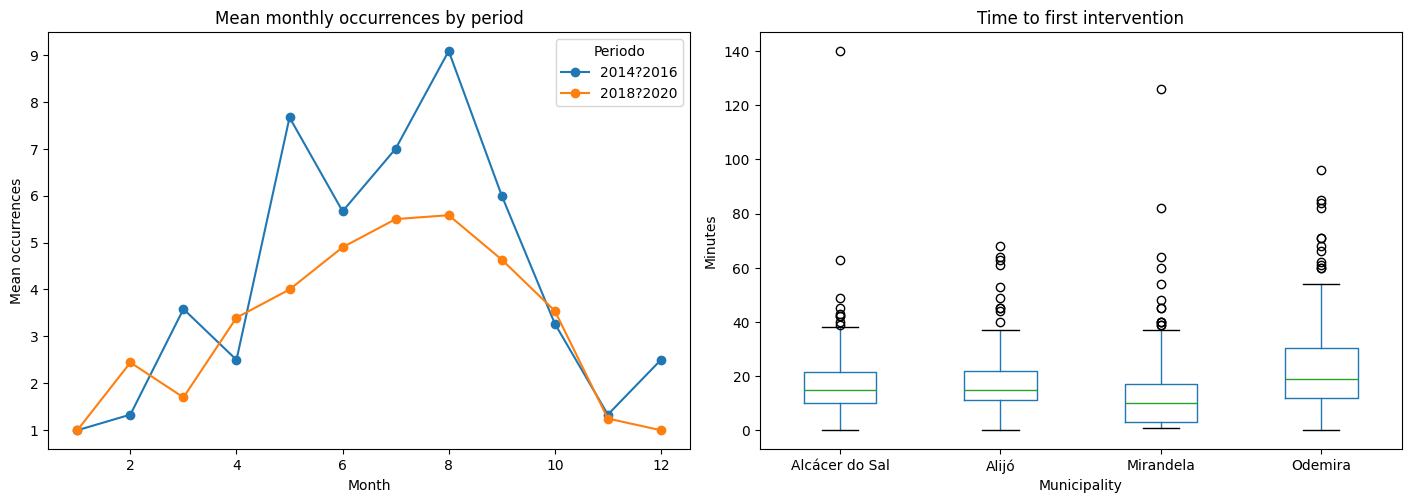

In [12]:
monthly_counts = (
    df.groupby(['Municipio', 'Periodo', 'Ano', 'Mes'])
    .size().rename('Ocorrencias').reset_index()
)
summary = df.groupby(['Municipio', 'Periodo']).agg(
    Ocorrencias=('Codigo_SGIF', 'size'),
    AreaTotal_media_ha=('AreaTotal_ha', 'mean'),
    FWI_medio=('FWI', 'mean'),
    Tempo_intervencao_mediano_min=('TempoPrimeiraIntervencao_min', 'median'),
).round(2)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
monthly_counts.groupby(['Periodo', 'Mes'])['Ocorrencias'].mean().unstack(0).plot(
    marker='o', ax=axes[0]
)
axes[0].set(title='Mean monthly occurrences by period', xlabel='Month', ylabel='Mean occurrences')
df.dropna(subset=['TempoPrimeiraIntervencao_min']).boxplot(
    column='TempoPrimeiraIntervencao_min', by='Municipio', ax=axes[1], grid=False
)
axes[1].set(title='Time to first intervention', xlabel='Municipality', ylabel='Minutes')
fig.suptitle('')
plt.show()


## Inference tests

The occurrence test compares the 36 municipality-month observations in each period. The response-time test excludes the missing intervention timestamp. Expected chi-square cell counts are displayed because small expected counts affect the reliability of the asymptotic approximation.


In [13]:
monthly_groups = [
    monthly_counts.loc[monthly_counts['Periodo'] == period, 'Ocorrencias']
    for period in ['2014?2016', '2018?2020']
]
occurrence_ttest = stats.ttest_ind(*monthly_groups, equal_var=False)
print('Welch t-test for monthly counts:', occurrence_ttest)

response_groups = [
    group['TempoPrimeiraIntervencao_min'].dropna().to_numpy()
    for _, group in df.groupby('Municipio', sort=True)
]
def welch_anova(groups):
    groups = [np.asarray(group, dtype=float) for group in groups]
    sample_sizes = np.array([len(group) for group in groups], dtype=float)
    means = np.array([group.mean() for group in groups])
    variances = np.array([group.var(ddof=1) for group in groups])
    weights = sample_sizes / variances
    weighted_mean = np.sum(weights * means) / np.sum(weights)
    correction_term = np.sum(
        (1 / (sample_sizes - 1))
        * (1 - weights / np.sum(weights)) ** 2
    )
    numerator = np.sum(weights * (means - weighted_mean) ** 2) / (len(groups) - 1)
    correction = 1 + (2 * (len(groups) - 2) / (len(groups) ** 2 - 1)) * correction_term
    statistic = numerator / correction
    denominator_df = (len(groups) ** 2 - 1) / (3 * correction_term)
    p_value = stats.f.sf(statistic, len(groups) - 1, denominator_df)
    return statistic, p_value, len(groups) - 1, denominator_df

response_anova = welch_anova(response_groups)
print('Welch ANOVA for response time (F, p, df1, df2):', response_anova)
display(df.groupby('Municipio')['TempoPrimeiraIntervencao_min'].agg(['count', 'mean', 'median', 'std']).round(2))


Welch t-test for monthly counts: TtestResult(statistic=np.float64(2.8114186933028917), pvalue=np.float64(0.005502032708654197), df=np.float64(172.96101841706889))
Welch ANOVA for response time (F, p, df1, df2): (np.float64(23.39760538430099), np.float64(4.585914375757855e-14), 3, np.float64(438.3353785254638))


,count,mean,median,std
Municipio,,,,
Alcácer do Sal,155,18.30,15.0,13.96
Alijó,186,17.77,15.0,11.88
Mirandela,301,12.70,10.0,13.21
Odemira,240,23.38,19.0,16.37


In [14]:
alert_table = pd.crosstab(df['Municipio'], df['FonteAlerta'])
chi_square = stats.chi2_contingency(alert_table)
expected = pd.DataFrame(chi_square.expected_freq, index=alert_table.index, columns=alert_table.columns)
print('Alert-source counts:')
display(alert_table)
print('Chi-square statistic, p-value, degrees of freedom:', chi_square[0], chi_square[1], chi_square[2])
print('Smallest expected count:', expected.min().min())


Alert-source counts:


FonteAlerta,112,117,CCO,Outros,PV,Populares,Sapadores
Municipio,,,,,,,
Alcácer do Sal,41,9,0,19,3,83,0
Alijó,33,43,18,14,19,59,1
Mirandela,46,42,26,28,53,99,7
Odemira,0,89,10,67,16,58,1


Chi-square statistic, p-value, degrees of freedom: 231.00929847859393 5.795900595866627e-39 18
Smallest expected count: 1.5780542986425339


In [15]:
public = df.assign(PublicAlert=df['FonteAlerta'].eq(PUBLIC_ALERT_SOURCE)).groupby('Periodo')['PublicAlert'].agg(['sum', 'count'])
public['proportion'] = public['sum'] / public['count']
pre, post = public.loc['2014?2016'], public.loc['2018?2020']
difference = post['proportion'] - pre['proportion']
se = np.sqrt(
    pre['proportion'] * (1 - pre['proportion']) / pre['count']
    + post['proportion'] * (1 - post['proportion']) / post['count']
)
ci = (difference - stats.norm.ppf(.975) * se, difference + stats.norm.ppf(.975) * se)
pooled = (pre['sum'] + post['sum']) / (pre['count'] + post['count'])
pooled_se = np.sqrt(pooled * (1 - pooled) * (1 / pre['count'] + 1 / post['count']))
z = difference / pooled_se
print('Public-alert definition:', PUBLIC_ALERT_SOURCE)
display(public)
print('Post-minus-pre difference:', difference)
print('95% confidence interval:', ci)
print('Two-proportion z-test:', z, 2 * stats.norm.sf(abs(z)))


Public-alert definition: Populares


,sum,count,proportion
Periodo,,,
2014?2016,236,515,0.458252
2018?2020,63,369,0.170732


Post-minus-pre difference: -0.2875207198673928
95% confidence interval: (np.float64(-0.3451898022594544), np.float64(-0.22985163747533124))
Two-proportion z-test: -8.910427687050973 5.083607755460142e-19


## 5. Burned area and cause classification

Two complementary variables are analyzed here: `AreaTotal_ha`, a quantitative measure of fire size, and `GrupoCausa`, a qualitative classification of the recorded cause. Because burned area is strongly right-skewed, the non-parametric Kruskal?Wallis test is used instead of ANOVA. Cause categories are grouped into the eight most frequent categories plus `Outros` to avoid an excessively sparse contingency table.


Burned-area summary by municipality:


,count,mean,median,std
Municipio,,,,
Alcácer do Sal,155,1.24,0.08,3.90
Alijó,187,17.40,0.18,98.17
Mirandela,301,3.91,0.12,26.01
Odemira,241,5.54,0.18,47.10


Kruskal-Wallis test for burned area: KruskalResult(statistic=np.float64(4.44065831626262), pvalue=np.float64(0.2176448998265229))


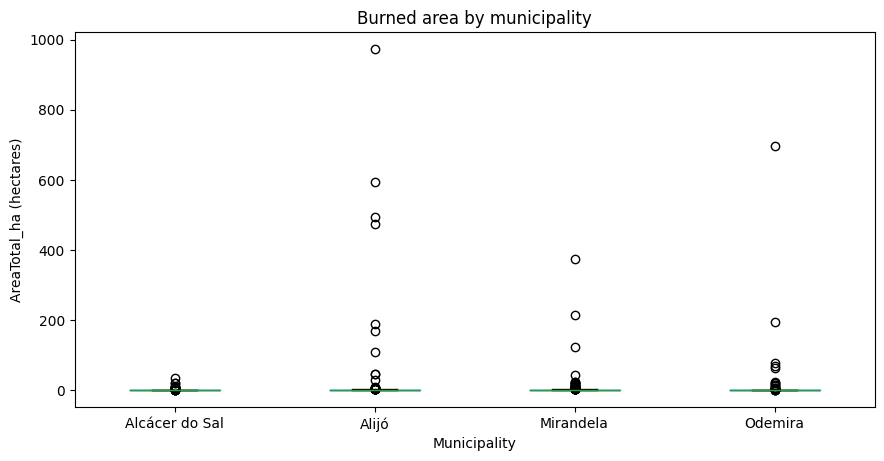

In [16]:
area_summary = df.groupby('Municipio')['AreaTotal_ha'].agg(['count', 'mean', 'median', 'std']).round(2)
area_groups = [group['AreaTotal_ha'].dropna().to_numpy() for _, group in df.groupby('Municipio', sort=True)]
area_test = stats.kruskal(*area_groups)
print('Burned-area summary by municipality:')
display(area_summary)
print('Kruskal-Wallis test for burned area:', area_test)

fig, ax = plt.subplots(figsize=(10, 5))
df.boxplot(column='AreaTotal_ha', by='Municipio', ax=ax, grid=False)
ax.set_title('Burned area by municipality')
ax.set_xlabel('Municipality')
ax.set_ylabel('AreaTotal_ha (hectares)')
fig.suptitle('')
plt.show()


In [17]:
top_causes = df['GrupoCausa'].value_counts(dropna=False).head(8).index
df['GrupoCausaAgrupado'] = df['GrupoCausa'].where(df['GrupoCausa'].isin(top_causes), 'Outros')
cause_table = pd.crosstab(df['Municipio'], df['GrupoCausaAgrupado'])
cause_test = stats.chi2_contingency(cause_table)
print('Most frequent cause groups:')
display(df['GrupoCausaAgrupado'].value_counts().to_frame('Ocorrencias'))
print('Cause groups by municipality:')
display(cause_table)
print('Chi-square statistic, p-value, degrees of freedom:', cause_test[0], cause_test[1], cause_test[2])
print('Smallest expected count:', cause_test[3].min())


Most frequent cause groups:


,Ocorrencias
GrupoCausaAgrupado,
Indeterminadas,259
Incendiarismo - Imputáveis,127
Outros,110
Queimadas de sobrantes florestais ou agrícolas,105
Queimas amontoados de sobrantes florestais ou agrícolas,94
Acidentais - Transportes e Comunicações,64
Acidentais - Maquinaria,58
Reacendimentos,30


Cause groups by municipality:


GrupoCausaAgrupado,Acidentais - Maquinaria,Acidentais - Transportes e Comunicações,Incendiarismo - Imputáveis,Indeterminadas,Outros,Queimadas de sobrantes florestais ou agrícolas,Queimas amontoados de sobrantes florestais ou agrícolas,Reacendimentos
Municipio,,,,,,,,
Alcácer do Sal,19,17,2,84,9,19,1,2
Alijó,1,1,61,24,27,20,19,4
Mirandela,12,6,52,82,48,48,26,24
Odemira,26,40,12,69,26,18,48,0


Chi-square statistic, p-value, degrees of freedom: 296.0158383307098 2.0556371391851322e-50 21
Smallest expected count: 5.419126328217238


## 6. Variables, hypotheses, and assumptions

**Qualitative variables:** `Municipio`, `Periodo`, `FonteAlerta`, and `GrupoCausa`. **Quantitative variables:** monthly occurrence count, `TempoPrimeiraIntervencao_min`, `AreaTotal_ha`, and `FWI`.

For each test, the null hypothesis states that there is no difference or association. A p-value below 0.05 is treated as evidence against the null hypothesis, but practical importance is evaluated using effect sizes and confidence intervals.


In [18]:
periods = sorted(df['Periodo'].dropna().unique())
pre_period, post_period = periods[0], periods[1]

pre_monthly = monthly_counts.loc[monthly_counts['Periodo'] == pre_period, 'Ocorrencias']
post_monthly = monthly_counts.loc[monthly_counts['Periodo'] == post_period, 'Ocorrencias']
mean_difference = post_monthly.mean() - pre_monthly.mean()
pooled_sd = np.sqrt(((len(pre_monthly) - 1) * pre_monthly.var(ddof=1) + (len(post_monthly) - 1) * post_monthly.var(ddof=1)) / (len(pre_monthly) + len(post_monthly) - 2))
cohens_d = mean_difference / pooled_sd
print('Period order:', pre_period, 'to', post_period)
print('Mean monthly occurrence difference (post - pre):', round(mean_difference, 2))
print("Cohen's d:", round(cohens_d, 2))
print('Levene test, monthly counts:', stats.levene(pre_monthly, post_monthly))
print('Levene test, response times:', stats.levene(*response_groups))


Period order: 2014?2016 to 2018?2020
Mean monthly occurrence difference (post - pre): -1.47
Cohen's d: -0.4
Levene test, monthly counts: LeveneResult(statistic=np.float64(9.330379036781796), pvalue=np.float64(0.002567341761224047))
Levene test, response times: LeveneResult(statistic=np.float64(5.130179113533401), pvalue=np.float64(0.0016029766181273031))


## 7. Post-hoc response-time comparisons

Since Welch ANOVA is significant, pairwise Welch t-tests identify which municipalities differ. The Holm correction controls the family-wise error rate across the six pairwise comparisons.


In [19]:
from itertools import combinations
response_by_municipality = {
    name: group['TempoPrimeiraIntervencao_min'].dropna().to_numpy()
    for name, group in df.groupby('Municipio', sort=True)
}
pairwise = []
for first, second in combinations(response_by_municipality, 2):
    result = stats.ttest_ind(response_by_municipality[first], response_by_municipality[second], equal_var=False)
    pairwise.append({'Municipio 1': first, 'Municipio 2': second, 'p_raw': result.pvalue})
pairwise = pd.DataFrame(pairwise).sort_values('p_raw').reset_index(drop=True)
m = len(pairwise)
pairwise['p_holm'] = (pairwise['p_raw'] * (m - pairwise.index)).clip(upper=1)
pairwise['Significativo_0.05'] = pairwise['p_holm'] < 0.05
pairwise


,Municipio 1,Municipio 2,p_raw,p_holm,Significativo_0.05
0,Mirandela,Odemira,2.534540e-15,1.520724e-14,True
1,Alijó,Mirandela,1.502758e-05,7.513790e-05,True
2,Alcácer do Sal,Mirandela,4.667801e-05,1.867120e-04,True
3,Alijó,Odemira,5.042569e-05,1.512771e-04,True
4,Alcácer do Sal,Odemira,1.084554e-03,2.169108e-03,True
5,Alcácer do Sal,Alijó,7.069570e-01,7.069570e-01,False


## 8. Interpretation guide

- A statistically significant result does not by itself establish causality.
- The four municipalities are a purposive comparison, not a random sample of Portugal.
- Monthly observations are seasonal and may not be fully independent.
- The alert-source and cause analyses describe recorded categories; they do not prove who caused or detected a fire in an absolute sense.
- Area burned is highly skewed, so medians and the Kruskal-Wallis result are more informative than means alone.
- Before submission, add the team members, validation date, and the email confirmation from `agomes@fe.up.pt`.


## Limitations and conclusions

Complete this section after reviewing the outputs. Discuss effect estimates and confidence intervals alongside p-values; the exclusion of 2017; seasonal dependence in monthly counts; the selected-municipality sample; the missing response timestamp; and the fact that observational comparisons do not establish causality.
